In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [2]:
import librosa
import os 
import numpy as np

In [3]:
!ls /kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/genres_stems/jazz/jazz.00000

bass.wav  drums.wav  other.wav	vocals.wav


## Q1

In [4]:
jazz_path = "/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/genres_stems/jazz"
durations = []
for song in os.listdir(jazz_path):
    song_path = os.path.join(jazz_path,song)
    if os.path.isdir(song_path):
      for file in os.listdir(song_path):
          if file.endswith(".wav"):
              file_path = os.path.join(song_path,file)
              duration = librosa.get_duration(path = file_path)
              durations.append(duration)
mean_duration = np.mean(durations)
mean_duration

np.float64(30.032979591836728)

## Q2

In [5]:
dataset_path = "/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/genres_stems"
sample_rate = set()
for genres in os.listdir(dataset_path):
    genre_path = os.path.join(dataset_path,genres)
    for song in os.listdir(genre_path):
        song_path = os.path.join(genre_path,song)
        for file in os.listdir(song_path):
            file_path = os.path.join(song_path,file)
            sr = librosa.get_samplerate(file_path)
            sample_rate.add(sr)
unique_sample_rate = sorted(sample_rate)
unique_sample_rate

[44100]

## Q3

In [6]:
dataset_path = "/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/genres_stems"

corrupted_count = 0 
for genres in os.listdir(dataset_path):
    genre_path = os.path.join(dataset_path,genres)
    for song in os.listdir(genre_path):
        song_path = os.path.join(genre_path,song)
        for file in os.listdir(song_path):
            file_path = os.path.join(song_path,file)
            # size check
            if os.path.getsize(file_path) == 0:
                corrupted_count +=1
                continue
            try:
               sr = librosa.get_samplerate(file_path)
            except:
                corrupted_count+= 1
corrupted_count

0

## Q4

In [7]:
peak_db_list =[]
dataset_path ="/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/genres_stems"
for genres in os.listdir(dataset_path):
    genre_path = os.path.join(dataset_path,genres)
    for song in os.listdir(genre_path):
        song_path = os.path.join(genre_path,song)
        for file in os.listdir(song_path):
            if "vocals.wav" in file.lower():
                file_path = os.path.join(song_path,file)
                y,sr = librosa.load(file_path,sr=None,mono=True)
                peak = np.max(np.abs(y))
                peak_db = 20* np.log10(peak+1e-10)
                peak_db_list.append(peak_db)
avg_peak_db = np.mean(peak_db_list)
avg_peak_db


np.float32(-12.494921)

## Q5

In [8]:
spectral_centroid=[]
blue_path = "/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/genres_stems/blues"
for song in os.listdir(blue_path):
    song_path = os.path.join(blue_path,song)
    for file in os.listdir(song_path):
        file_path = os.path.join(song_path,file)
        y,sr = librosa.load(file_path,sr=None,mono=True)
        cent = librosa.feature.spectral_centroid(y=y,sr=sr)
        mean_cent = np.mean(cent) #mean across time frames
        spectral_centroid.append(mean_cent)
mean_sc = np.mean(spectral_centroid)
mean_sc
        

np.float64(2296.7827371150856)

## q6

In [9]:
genre_mean_cent={}
dataset_path="/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/genres_stems"
for genre in os.listdir(dataset_path):
    genre_path = os.path.join(dataset_path,genre)
    all_cent = []
    for song in os.listdir(genre_path):
        song_path = os.path.join(genre_path,song)
        for file in os.listdir(song_path):
            file_path = os.path.join(song_path,file)
            y,sr = librosa.load(file_path,sr=None,mono=True)
            cent = librosa.feature.spectral_centroid(y=y,sr=sr)
            mean_cent = np.mean(cent)
            all_cent.append(mean_cent)
    if all_cent:
        genre_mean_cent[genre] = np.mean(all_cent)
print(genre_mean_cent)
    
    



{'disco': np.float64(2454.1533850826813), 'metal': np.float64(2579.3243146551536), 'reggae': np.float64(2404.568992703987), 'blues': np.float64(2296.7827371150856), 'rock': np.float64(2250.0843332686527), 'classical': np.float64(1674.7903261564497), 'jazz': np.float64(2544.1149574413557), 'hiphop': np.float64(2370.789957346027), 'country': np.float64(2266.7210020485495), 'pop': np.float64(2440.884880560034)}


## Q7

In [10]:
dataset_path = "/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/genres_stems"
count = 0 
threshold = 1e-4 #silence threshold
for genre in os.listdir(dataset_path):
    genre_path = os.path.join(dataset_path,genre)
    for song in os.listdir(genre_path):
        song_path = os.path.join(genre_path,song)
        for file in os.listdir(song_path):
            file_path = os.path.join(song_path,file)
            y,sr = librosa.load(file_path,duration=0.5,sr=None,mono=True)
            #check all samples
            if np.max(np.abs(y))<threshold:
                count+=1
count
            

333

/tmp/ipykernel_17/3398690809.py:23: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return [float(tempo), spec_cent, zcr, rolloff]


Validation Macro F1 Score: 0.2012

Detailed Classification Report:
              precision    recall  f1-score   support

       blues       0.00      0.00      0.00        20
   classical       0.00      0.00      0.00        20
     country       0.18      0.35      0.24        20
       disco       0.26      0.25      0.26        20
      hiphop       0.60      0.15      0.24        20
        jazz       0.19      0.20      0.20        20
       metal       0.32      0.60      0.41        20
         pop       0.19      0.30      0.23        20
      reggae       0.44      0.35      0.39        20
        rock       0.05      0.05      0.05        20

    accuracy                           0.23       200
   macro avg       0.22      0.23      0.20       200
weighted avg       0.22      0.23      0.20       200



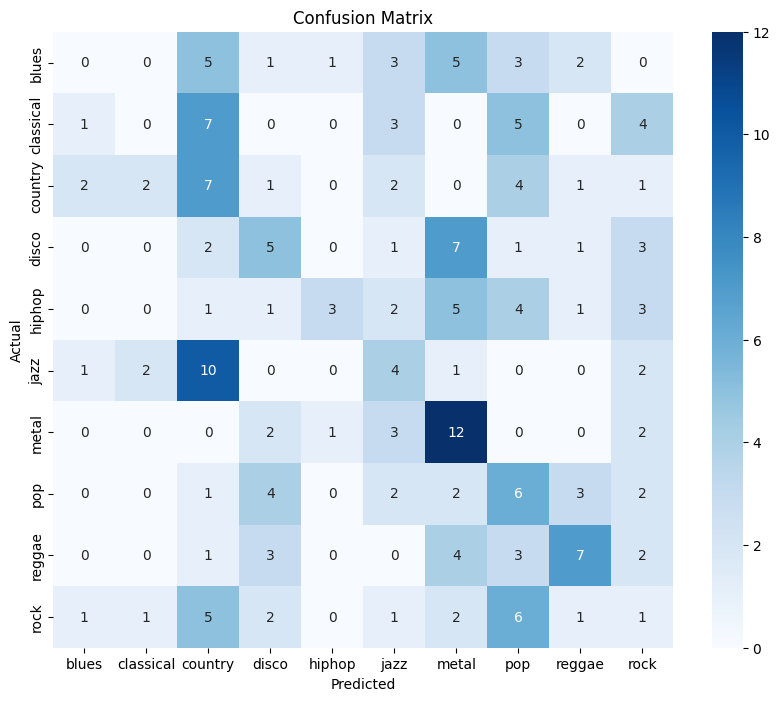


Genre: blues
TP: 0, FP: 5, FN: 20, TN: 175

Genre: classical
TP: 0, FP: 5, FN: 20, TN: 175

Genre: country
TP: 7, FP: 32, FN: 13, TN: 148

Genre: disco
TP: 5, FP: 14, FN: 15, TN: 166

Genre: hiphop
TP: 3, FP: 2, FN: 17, TN: 178

Genre: jazz
TP: 4, FP: 17, FN: 16, TN: 163

Genre: metal
TP: 12, FP: 26, FN: 8, TN: 154

Genre: pop
TP: 6, FP: 26, FN: 14, TN: 154

Genre: reggae
TP: 7, FP: 9, FN: 13, TN: 171

Genre: rock
TP: 1, FP: 19, FN: 19, TN: 161


In [11]:
import os
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score, confusion_matrix, classification_report

# --- 1. Setup and Preprocessing ---
ROOT = '/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup'
STEMS_PATH = os.path.join(ROOT, 'genres_stems')
GENRES = ["blues", "classical", "country", "disco", "hiphop", "jazz", "metal", "pop", "reggae", "rock"]

def extract_features(song_path):
    # Load 10s at 22050Hz
    y, sr = librosa.load(os.path.join(song_path, 'other.wav'), sr=22050, duration=10)
    tempo, _ = librosa.beat.beat_track(y=y, sr=sr)
    spec_cent = np.mean(librosa.feature.spectral_centroid(y=y, sr=sr))
    zcr = np.mean(librosa.feature.zero_crossing_rate(y))
    rolloff = np.mean(librosa.feature.spectral_rolloff(y=y, sr=sr))
    return [float(tempo), spec_cent, zcr, rolloff]

# --- 2. Data Preparation & Stratified Split ---
data = []
for g in GENRES:
    gp = os.path.join(STEMS_PATH, g)
    songs = [s for s in os.listdir(gp) if os.path.isdir(os.path.join(gp, s))]
    for s in songs: # Sampling 50 for speed; use all for final
        data.append({'path': os.path.join(gp, s), 'genre': g})

df = pd.DataFrame(data)
train_df, val_df = train_test_split(df, test_size=0.2, stratify=df['genre'], random_state=42)

# --- 3. Model Training (Decision Tree) ---
X_train = np.array([extract_features(p) for p in train_df['path']])
y_train = train_df['genre']
X_val = np.array([extract_features(p) for p in val_df['path']])
y_val = val_df['genre']

clf = DecisionTreeClassifier(max_depth=5, random_state=42)
clf.fit(X_train, y_train)


y_pred = clf.predict(X_val) # COMPUTE PREDICTED VALUES
macro_f1 = f1_score(y_val,y_pred,average='macro')# COMPUTE VALIDATION MACRO F1 SCORE
cm = confusion_matrix(y_val,y_pred,labels=GENRES)# COMPUTE CONFUSION MATRIX
cr = classification_report(y_val,y_pred,target_names=GENRES) # COMPUTE CLASSIFICATION REPORT



print(f"Validation Macro F1 Score: {macro_f1:.4f}\n")
print("Detailed Classification Report:")
print(cr)


plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=GENRES,
            yticklabels=GENRES)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# computation of tp,tn,fp,fn

for i, genre in enumerate(GENRES):
    TP = cm[i, i]
    FP = cm[:, i].sum() - TP
    FN = cm[i, :].sum() - TP
    TN = cm.sum() - (TP + FP + FN)
    
    print(f"\nGenre: {genre}")
    print(f"TP: {TP}, FP: {FP}, FN: {FN}, TN: {TN}")

